In [40]:
# Importar bibliotecas
import zipfile
from numpy import info
import pandas as pd
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# Instanciar o LabelEncoder
le = LabelEncoder()

In [41]:
import requests
import zipfile
import io
import os

url = "https://raw.githubusercontent.com/especializacao-ia-pucsp/grupo-01-projeto_supervisionado-II/main/data/processed/dados_processados.zip"

resposta = requests.get(url)
resposta.raise_for_status()

with zipfile.ZipFile(io.BytesIO(resposta.content)) as arquivo_zip:
    print("Arquivos encontrados no ZIP:")
    for nome in arquivo_zip.namelist():
        print(nome)

    arquivo_zip.extractall("data/processed")

Arquivos encontrados no ZIP:
X_treino.csv
X_val.csv
X_teste.csv
y_treino.csv
y_val.csv
y_teste.csv


In [42]:
# Carrega bases de treino, validação e teste

X_treino_df = pd.read_csv('data/processed/X_treino.csv')
display(X_treino_df.head())

y_treino_df = pd.read_csv('data/processed/y_treino.csv')
display(y_treino_df.head())

X_teste_df = pd.read_csv('data/processed/X_teste.csv')
display(X_teste_df.head())

y_teste_df = pd.read_csv('data/processed/y_teste.csv')
display(y_teste_df.head())

X_val_df = pd.read_csv('data/processed/X_val.csv')
display(X_val_df.head())

y_val_df = pd.read_csv('data/processed/y_val.csv')
display(y_val_df.head())

,historical_tickets,sla_hours,resolution_time_hours,image_width,image_height,sentiment_score,num_words,num_images_x,latitude,longitude,...,priority_Baixa,priority_Crítica,priority_Média,status_Aberto,status_Em andamento,status_Fechado,assigned_team_Aplicações,assigned_team_Infra,assigned_team_N1,assigned_team_N2
0,-0.501715,-0.704413,0.815095,-0.478589,-0.491344,-1.022203,-0.214642,-1.332575,-0.497740,0.468707,...,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
1,0.090169,-0.704413,-0.145479,-0.478589,-0.491344,1.726922,0.628414,-1.332575,-1.099546,0.591982,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2,0.851164,-0.704413,1.631582,-2.068180,3.116287,-0.405931,1.471469,-1.332575,1.625253,-1.530947,...,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
3,1.443048,-0.957453,-0.673794,0.527254,0.454713,-0.784645,-0.214642,0.436878,-0.960263,0.135556,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,0.005614,-0.704413,-1.682396,-0.478589,-0.491344,-1.010153,-1.900753,-1.332575,-0.970147,-1.230824,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0


,target_category
0,RH
1,Rede
2,RH
3,Acesso
4,Acesso


,historical_tickets,sla_hours,resolution_time_hours,image_width,image_height,sentiment_score,num_words,num_images_x,latitude,longitude,...,priority_Baixa,priority_Crítica,priority_Média,status_Aberto,status_Em andamento,status_Fechado,assigned_team_Aplicações,assigned_team_Infra,assigned_team_N1,assigned_team_N2
0,1.443048,-0.957453,1.631582,-0.478589,-0.466116,-0.905146,0.628414,-1.332575,-0.499889,-0.862983,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,-0.248050,-0.957453,0.959181,-0.478589,-0.491344,-1.416410,-0.214642,1.321605,-0.642435,1.543005,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2,-0.417160,-0.451373,1.679611,0.527254,-0.352589,0.673407,0.628414,-0.447849,0.188006,0.234262,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,1.443048,0.307747,1.631582,-0.478589,-0.491344,1.646015,0.628414,0.436878,-0.168067,-0.835777,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4,1.696713,-0.451373,0.046636,-2.068180,3.116287,1.219100,-0.214642,-0.447849,-1.153210,0.610305,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


,target_category
0,Hardware
1,Rede
2,Financeiro
3,Software
4,Acesso


,historical_tickets,sla_hours,resolution_time_hours,image_width,image_height,sentiment_score,num_words,num_images_x,latitude,longitude,...,priority_Baixa,priority_Crítica,priority_Média,status_Aberto,status_Em andamento,status_Fechado,assigned_team_Aplicações,assigned_team_Infra,assigned_team_N1,assigned_team_N2
0,0.343834,0.307747,-0.769852,0.527254,0.454713,0.225835,0.628414,-0.447849,0.394727,-0.820039,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.343834,0.307747,1.199324,-0.478589,-0.491344,-0.309530,-1.900753,-1.332575,1.491850,1.541550,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,-1.178155,0.307747,0.094665,-0.478589,-0.491344,1.048678,-1.057698,1.321605,0.219069,1.114016,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3,-1.262710,1.825988,-0.241536,-0.478589,-0.491344,0.828335,-1.900753,-0.447849,0.421708,-0.112720,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
4,-1.009045,1.825988,-1.586339,-0.478589,-0.377817,0.917850,0.628414,1.321605,-0.267724,1.674138,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0


,target_category
0,RH
1,Software
2,Software
3,Acesso
4,Rede


In [43]:
# Tabular classes a serem classificadas
frequency_table = y_treino_df['target_category'].value_counts().reset_index()
frequency_table.columns = ['target_category', 'count']
display(frequency_table)

,target_category,count
0,Software,535
1,Rede,516
2,Hardware,501
3,RH,493
4,Acesso,493
5,Financeiro,462


In [44]:
# Ajustar o LabelEncoder usando as categorias originais do treino

y_treino_df = pd.read_csv('data/processed/y_treino.csv')
y_val_df = pd.read_csv('data/processed/y_val.csv')
y_teste_df = pd.read_csv('data/processed/y_teste.csv')

le.fit(y_treino_df['target_category'])

# Aplicar o LabelEncoder aos dados de treino
y_treino_df['target_category'] = le.transform(
    y_treino_df['target_category']
)
display(y_treino_df.head())

# Aplicar o LabelEncoder aos dados de teste
y_teste_df['target_category'] = le.transform(
    y_teste_df['target_category']
)
display(y_teste_df.head())

# Aplicar o LabelEncoder aos dados de validação
y_val_df['target_category'] = le.transform(
    y_val_df['target_category']
)
display(y_val_df.head())

,target_category
0,3
1,4
2,3
3,0
4,0


,target_category
0,2
1,4
2,1
3,5
4,0


,target_category
0,3
1,5
2,5
3,0
4,4


In [45]:
# Configurar o modelo MLP
mlp = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    solver='adam',
    alpha=0.0001,
    batch_size=200,
    max_iter=50,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    random_state=42,
    verbose=True
)

# Treinar o modelo MLP com os dados de treino
mlp.fit(
    X_treino_df,
    y_treino_df['target_category']
)

print("Modelo MLP treinado com sucesso!")

Iteration 1, loss = 1.79633323
Validation score: 0.243333
Iteration 2, loss = 1.69925231
Validation score: 0.290000
Iteration 3, loss = 1.62225032
Validation score: 0.316667
Iteration 4, loss = 1.55212584
Validation score: 0.350000
Iteration 5, loss = 1.49830638
Validation score: 0.383333
Iteration 6, loss = 1.45466803
Validation score: 0.390000
Iteration 7, loss = 1.41867733
Validation score: 0.396667
Iteration 8, loss = 1.38881814
Validation score: 0.410000
Iteration 9, loss = 1.35835634
Validation score: 0.440000
Iteration 10, loss = 1.33059377
Validation score: 0.413333
Iteration 11, loss = 1.30268712
Validation score: 0.433333
Iteration 12, loss = 1.27243204
Validation score: 0.443333
Iteration 13, loss = 1.24523516
Validation score: 0.453333
Iteration 14, loss = 1.21444897
Validation score: 0.450000
Iteration 15, loss = 1.18942195
Validation score: 0.473333
Iteration 16, loss = 1.16124705
Validation score: 0.440000
Iteration 17, loss = 1.13778479
Validation score: 0.450000
Iterat

In [46]:
# Métricas finais
y_pred = mlp.predict(X_teste_df)
accuracy = accuracy_score(y_teste_df, y_pred)
print(f"Acurácia no teste: {accuracy:.4f}")
print(f"Número de iterações realizadas: {mlp.n_iter_}")
print(f"Perda final (loss): {mlp.loss_}")

Acurácia no teste: 0.4320
Número de iterações realizadas: 26
Perda final (loss): 0.933247219746624


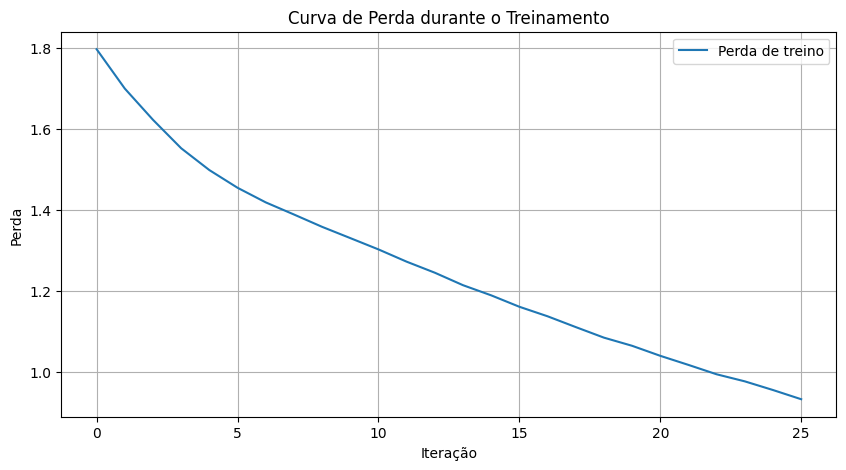

In [47]:
# Plotar a loss curve
plt.figure(figsize=(10, 5))
plt.plot(mlp.loss_curve_, label='Perda de treino')
plt.xlabel('Iteração')
plt.ylabel('Perda')
plt.title('Curva de Perda durante o Treinamento')
plt.grid(True)
plt.legend()
plt.show()

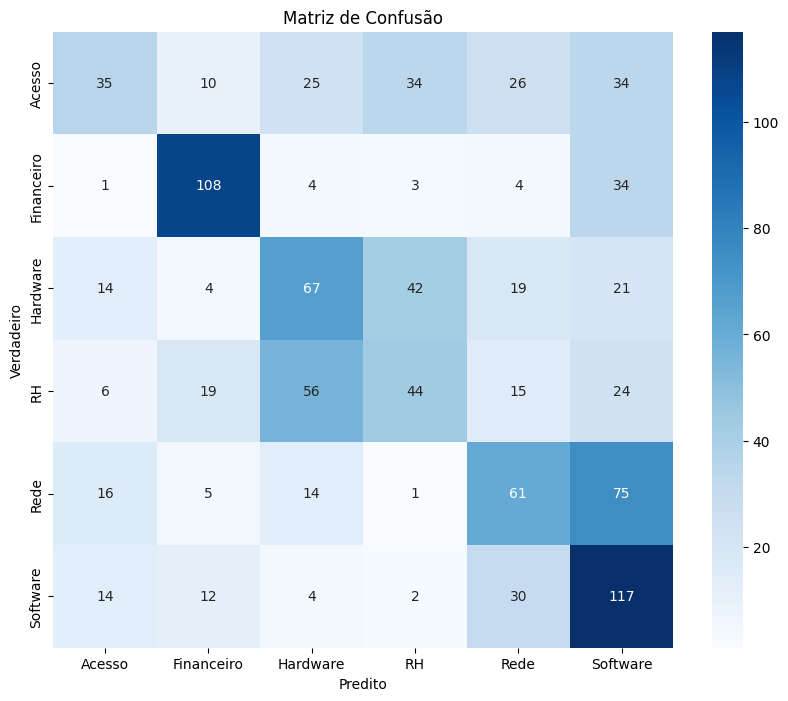


Métricas de avaliação:

              precision    recall  f1-score   support

      Acesso       0.41      0.21      0.28       164
  Financeiro       0.68      0.70      0.69       154
    Hardware       0.39      0.40      0.40       167
          RH       0.35      0.27      0.30       164
        Rede       0.39      0.35      0.37       172
    Software       0.38      0.65      0.48       179

    accuracy                           0.43      1000
   macro avg       0.44      0.43      0.42      1000
weighted avg       0.43      0.43      0.42      1000



In [48]:
# Matriz de confusão
# y_teste_df['target_category'] já está transformado em numérico, então podemos usá-lo diretamente
y_teste_transformed = y_teste_df['target_category']

# Obter os nomes das classes para o heatmap e relatório
class_names = le.classes_

cm = confusion_matrix(y_teste_transformed, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predito')
plt.ylabel('Verdadeiro')
plt.title('Matriz de Confusão')
plt.show()

# Métricas de avaliação
print("\nMétricas de avaliação:\n")
print(classification_report(y_teste_transformed, y_pred, target_names=class_names))

## Conclusões dessa versão

Realizamos o treinamento e a avaliação de um modelo Multi-Layer Perceptron (MLP) para classificação das categorias dos dados.

### Avaliação do modelo

- **Acurácia:** O modelo alcançou uma acurácia de **43%** no conjunto de teste, conforme o relatório de classificação.
- **Curva de perda:** A curva de perda durante o treinamento apresentou convergência gradual, indicando que o modelo estava aprendendo ao longo das épocas. A convergência, isoladamente, não garante um bom desempenho de classificação.
- **Matriz de confusão e métricas:** A classe Financeiro apresentou o melhor desempenho geral, com F1-score de 0,69. A classe Software obteve recall de 0,65, mas precisão de 0,38. Já a classe Acesso apresentou os menores resultados, com recall de 0,21 e F1-score de 0,28, evidenciando dificuldades na identificação dessa categoria.

De forma geral, os resultados indicam que o modelo ainda apresenta limitações na classificação das seis categorias, mostrando espaço para melhorias.
